# Predicción de ROP — Pozos de Noruega
## Modelado y comparación de algoritmos de regresión

**Variable target:** `Rate of Penetration m/h` (ROP)  
**Datasets:** `conjunto_limpio_balanceado.csv` (8.473 filas) y `conjunto_limpio.csv` (34.456 filas)  
**Estrategia de validación:** Leave-One-Well-Out (LOWO) + Bloques de 100 m + holdout final en Pozo 5 (908 filas)

---

### Modelos evaluados
| # | Modelo | Tipo |
|---|---|---|
| 0 | **Baseline (Media / `DummyRegressor`)** | Piso de referencia (predice siempre la media del entrenamiento) |
| 1 | **Linear Regression** | Modelo lineal estándar |
| 2 | **Ridge Regression** | Lineal regularizado ($L_2$) |
| 3 | **Random Forest** | Ensamble de árboles (*bagging*), captura no-linealidades |
| 4 | **XGBoost** | *Gradient boosting* de árboles |
| 5 | **MLP (`MLPRegressor`)** | Red neuronal perceptrón multicapa |

Partimos de los análisis anteriores de los pozos 0, 1, 2, 3, 4, 5 y 6, donde terminamos obteniendo un dataset limpio (usando únicamente mediciones reales, sin relleno artificial) para el entrenamiento de modelos de regresión. A partir de dichos análisis se obtuvieron dos archivos CSV principales: uno balanceado a una fila por metro de profundidad con 8.473 filas y otro con todas las mediciones reales completas, de 34.456 filas. El Pozo 5 (908 filas) se reservó sin explorar como conjunto de prueba final (*holdout*).

In [ ]:
# Instalar XGBoost si no está disponible
!pip install xgboost --quiet

In [1]:
import os
import warnings
warnings.filterwarnings('ignore')

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.dummy import DummyRegressor
from sklearn.linear_model import LinearRegression, Ridge
from sklearn.ensemble import RandomForestRegressor
from sklearn.neural_network import MLPRegressor
from sklearn.preprocessing import RobustScaler
from sklearn.metrics import r2_score, mean_squared_error, mean_absolute_error
from sklearn.model_selection import train_test_split, GroupKFold
from sklearn.pipeline import Pipeline
from xgboost import XGBRegressor

SEED = 42
TARGET = 'Rate of Penetration m/h'
POZO_TEST = 5
POZOS = [0, 1, 2, 3, 4, 6]

plt.rcParams['figure.dpi'] = 120
plt.rcParams['font.size'] = 11
print('Librerías cargadas correctamente.')

Librerías cargadas correctamente.


## 1. Carga de datos

Los archivos fueron generados por el notebook `ROP_Noruega_Resto_Pozos_Entrenamiento_Sin_Relleno.ipynb`.

In [2]:
# Si los CSV están en la carpeta actual usa ruta local; si no, ajustar la ruta (ej. Google Drive)
RUTA_BASE = '' if os.path.exists('conjunto_limpio_balanceado.csv') else '/home/valentin/Escritorio/ypf/YPF-rop-predictor/'

bal  = pd.read_csv(RUTA_BASE + 'conjunto_limpio_balanceado.csv')
full = pd.read_csv(RUTA_BASE + 'conjunto_limpio.csv')
test_p5 = pd.read_csv(RUTA_BASE + 'USROP_A 5 sin relleno.csv')

print(f'Balanceado:  {bal.shape[0]:,} filas × {bal.shape[1]} columnas')
print(f'Completo:    {full.shape[0]:,} filas × {full.shape[1]} columnas')
print(f'Test (P5):   {test_p5.shape[0]:,} filas × {test_p5.shape[1]} columnas')
bal.head()

Balanceado:  8,473 filas × 11 columnas
Completo:    34,456 filas × 11 columnas
Test (P5):   908 filas × 10 columnas


,Measured Depth m,Weight on Bit kkgf,Average Standpipe Pressure kPa,Average Surface Torque kN.m,Rate of Penetration m/h,Average Rotary Speed rpm,Mud Flow In L/min,Diameter mm,Average Hookload kkgf,Hole Depth (TVD) m,pozo
0,489.509,6.164320,9521.246136,0.352513,41.897808,84.0,2784.321942,311.15,94.111345,489.252768,0
1,490.118,6.431940,9319.919223,0.284722,43.671744,84.0,2784.321942,311.15,94.124953,489.855967,0
2,491.033,5.842270,9440.922214,0.244047,42.864024,84.0,2784.321942,311.15,93.780222,490.760309,0
3,492.100,6.023707,9279.998579,0.013558,41.675304,84.0,2784.321942,311.15,93.934444,491.815222,0
4,493.166,4.354487,9242.766889,0.000000,33.204912,84.0,2784.321942,311.15,95.993753,492.869830,0


## 2. EDA rápido de los pozos de entrenamiento

Revisamos la distribución del target, la correlación con las variables predictoras y las diferencias de profundidad y diámetro de mecha entre los 6 pozos de entrenamiento (`0, 1, 2, 3, 4, 6`), manteniendo el Pozo 5 reservado sin tocar hasta la evaluación final.

In [3]:
print('Tipos de columnas:')
print(bal.dtypes)
print('\nNulos por columna:')
print(bal.isna().sum())
print('\nFilas por pozo:')
print(bal['pozo'].value_counts().sort_index())

Tipos de columnas:
Measured Depth m                  float64
Weight on Bit kkgf                float64
Average Standpipe Pressure kPa    float64
Average Surface Torque kN.m       float64
Rate of Penetration m/h           float64
Average Rotary Speed rpm          float64
Mud Flow In L/min                 float64
Diameter mm                       float64
Average Hookload kkgf             float64
Hole Depth (TVD) m                float64
pozo                                int64

Nulos por columna:
Measured Depth m                  0
Weight on Bit kkgf                0
Average Standpipe Pressure kPa    0
Average Surface Torque kN.m       0
Rate of Penetration m/h           0
Average Rotary Speed rpm          0
Mud Flow In L/min                 0
Diameter mm                       0
Average Hookload kkgf             0
Hole Depth (TVD) m                0
pozo                              0

Filas por pozo:
pozo
0     603
1     554
2    1979
3    2518
4    2451
6     368


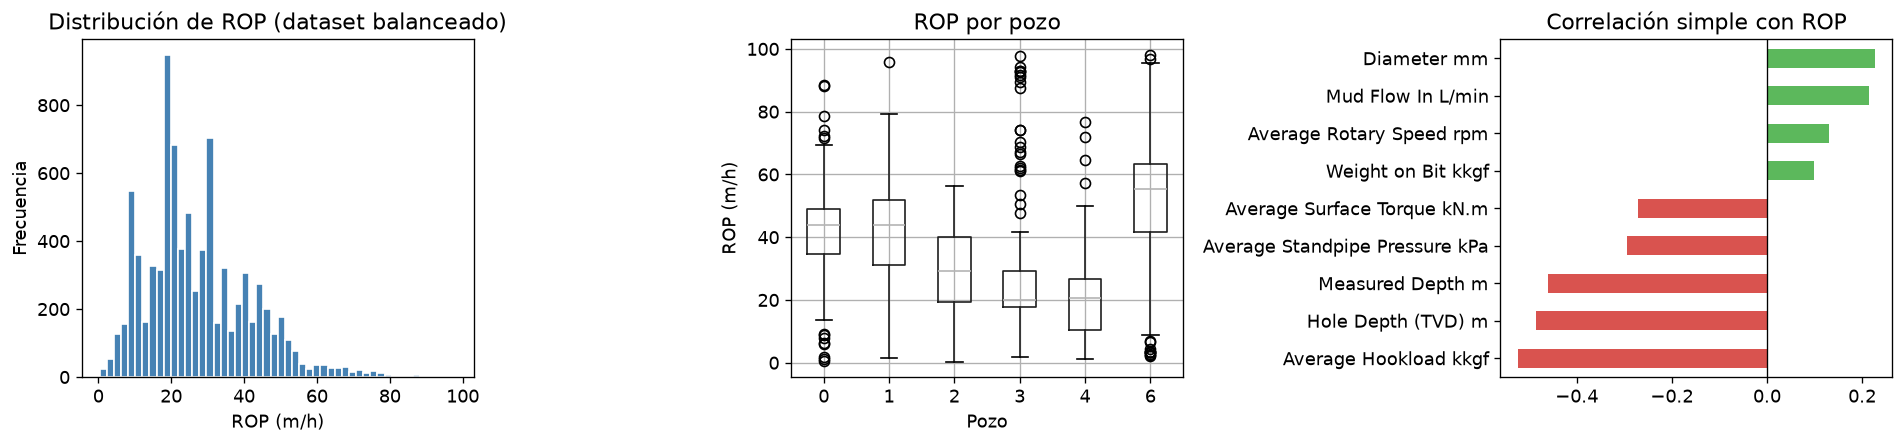

In [4]:
fig, axes = plt.subplots(1, 3, figsize=(16, 4))

# Distribución del target
axes[0].hist(bal[TARGET], bins=50, color='steelblue', edgecolor='white')
axes[0].set_title('Distribución de ROP (dataset balanceado)')
axes[0].set_xlabel('ROP (m/h)')
axes[0].set_ylabel('Frecuencia')

# ROP por pozo (boxplot)
bal.boxplot(column=TARGET, by='pozo', ax=axes[1])
axes[1].set_title('ROP por pozo')
axes[1].set_xlabel('Pozo')
axes[1].set_ylabel('ROP (m/h)')
plt.sca(axes[1]); plt.title('ROP por pozo')

# Correlación con ROP (excluyendo ID de pozo)
features_num = bal.select_dtypes(include='number').drop(columns=[TARGET, 'pozo'])
corr = features_num.corrwith(bal[TARGET]).sort_values()
corr.plot(kind='barh', ax=axes[2], color=['#d9534f' if v < 0 else '#5cb85c' for v in corr])
axes[2].set_title('Correlación simple con ROP')
axes[2].axvline(0, color='black', linewidth=0.8)

plt.suptitle('')
plt.tight_layout()
plt.show()

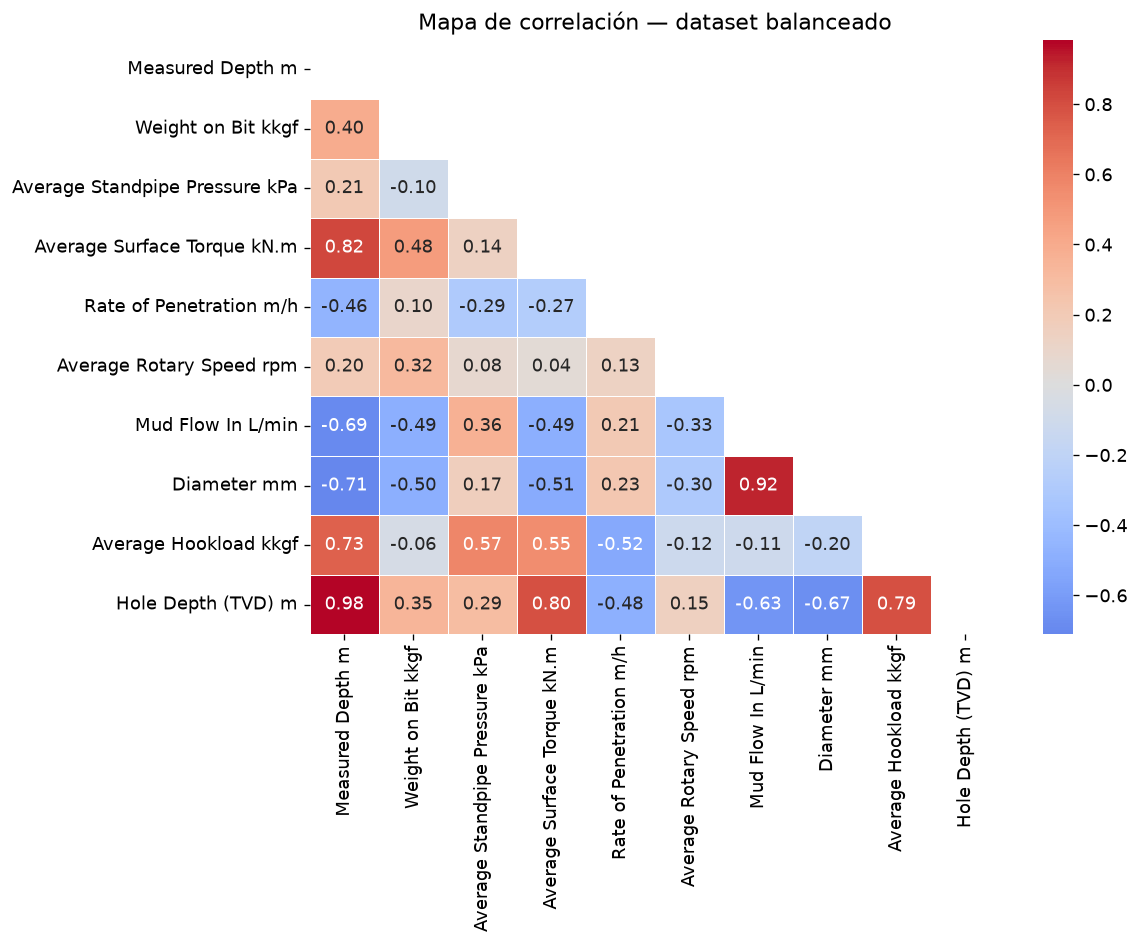


Nota: Measured Depth m y Hole Depth (TVD) m tienen alta multicolinealidad (VIF > 50).
Además, la profundidad presenta confusión (depth confounding) con el diámetro y el ROP entre pozos.


In [5]:
fig, ax = plt.subplots(figsize=(10, 8))
corr_matrix = bal.select_dtypes(include='number').drop(columns=['pozo']).corr()
mask = np.triu(np.ones_like(corr_matrix, dtype=bool))
sns.heatmap(corr_matrix, mask=mask, annot=True, fmt='.2f', cmap='coolwarm',
            center=0, ax=ax, linewidths=0.5)
ax.set_title('Mapa de correlación — dataset balanceado')
plt.tight_layout()
plt.show()

print('\nNota: Measured Depth m y Hole Depth (TVD) m tienen alta multicolinealidad (VIF > 50).')
print('Además, la profundidad presenta confusión (depth confounding) con el diámetro y el ROP entre pozos.')

### Estructura de los 6 pozos de entrenamiento: profundidad, diámetro de mecha y ROP

En el Notebook 2 comprobamos que los 6 pozos de entrenamiento tienen rangos operativos válidos luego de la limpieza, pero **cubren tramos de profundidad y diámetros muy distintos**:
- Los **Pozos 1 y 6** son exclusivamente superficiales ($< 1.000\text{ m}$), perforados con mecha de $17,5\text{''}$ ($444,5\text{ mm}$) y tienen los ROP promedio más altos ($43,0\text{ y }51,9\text{ m/h}$).
- Los **Pozos 3 y 4** son los únicos que superan los $3.500\text{ m}$ y tienen los ROP promedio más bajos ($22,2\text{ y }20,7\text{ m/h}$).
- Como los archivos oficiales no incluyen `Gamma Ray` en todos los pozos, el modelo **no dispone de una variable de litología** para saber en qué roca está; si dejamos `Measured Depth m`, un modelo puede aprender por error que toda profundidad $> 2.800\text{ m}$ implica necesariamente un ROP lento ($\sim 21\text{ m/h}$).

,Pozo,Filas (bal),MD mín–máx (m),Diámetros (mm),ROP media (m/h),ROP std (m/h)
0,Pozo 0,603,490–1205,"215.9, 311.1",41.3,11.7
1,Pozo 1,554,277–914,444.5,43.0,15.3
2,Pozo 2,1979,1050–3466,"215.9, 311.1, 444.5",29.2,12.8
3,Pozo 3,2518,1297–4065,"215.9, 444.5",22.2,9.3
4,Pozo 4,2451,1381–4090,"215.9, 311.1",20.7,9.9
5,Pozo 6,368,219–632,444.5,51.9,19.3


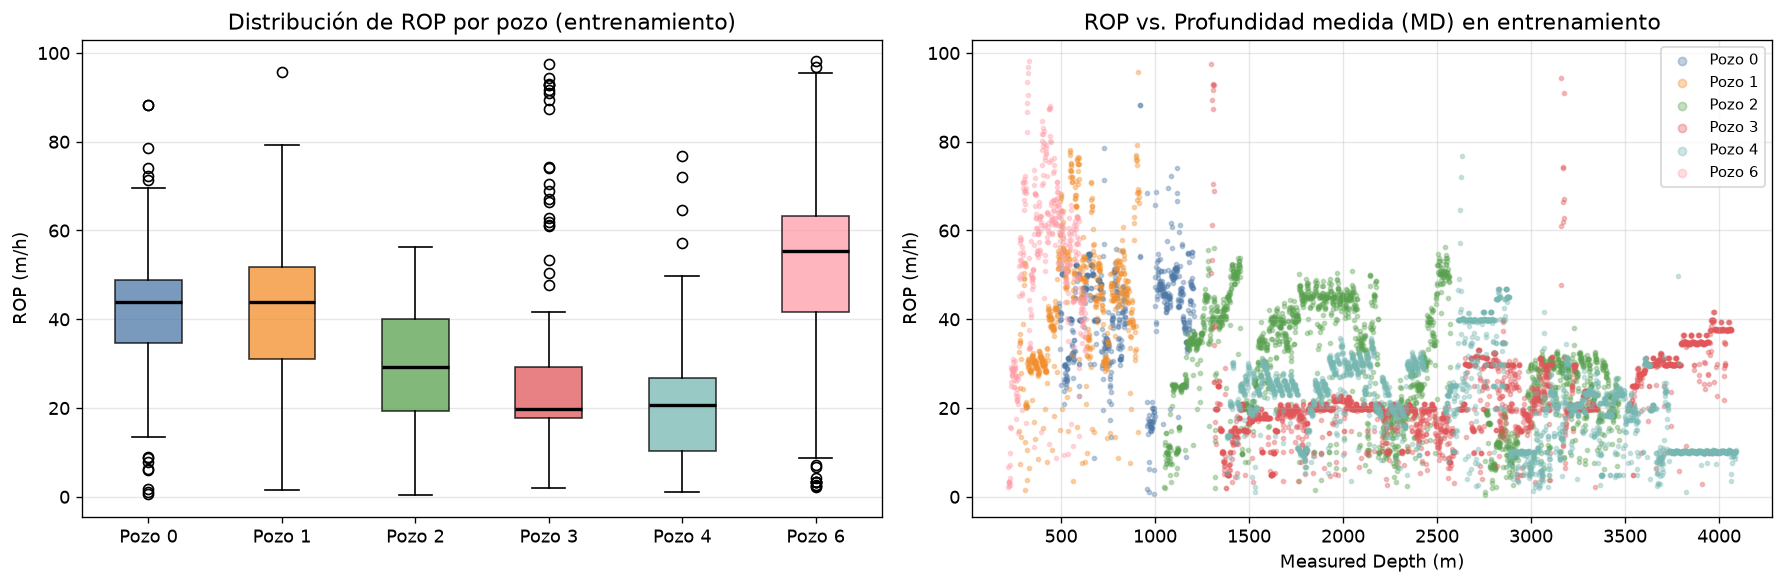

In [6]:
resumen_pozos = []
for p in POZOS:
    sub = bal[bal['pozo'] == p]
    diams = ', '.join([f'{d:.1f}' for d in sorted(sub['Diameter mm'].unique())])
    resumen_pozos.append({
        'Pozo': f'Pozo {p}',
        'Filas (bal)': len(sub),
        'MD mín–máx (m)': f"{sub['Measured Depth m'].min():.0f}–{sub['Measured Depth m'].max():.0f}",
        'Diámetros (mm)': diams,
        'ROP media (m/h)': round(sub[TARGET].mean(), 1),
        'ROP std (m/h)': round(sub[TARGET].std(), 1)
    })
df_resumen_pozos = pd.DataFrame(resumen_pozos)
display(df_resumen_pozos)

fig, axes = plt.subplots(1, 2, figsize=(15, 5))
data_por_pozo = [bal[bal['pozo'] == p][TARGET].values for p in POZOS]
bp = axes[0].boxplot(data_por_pozo, patch_artist=True, medianprops={'color': 'black', 'linewidth': 2})
colores_p = ['#4e79a7','#f28e2b','#59a14f','#e15759','#76b7b2','#ff9da7']
for patch, color in zip(bp['boxes'], colores_p):
    patch.set_facecolor(color); patch.set_alpha(0.75)
axes[0].set_xticks(range(1, len(POZOS) + 1))
axes[0].set_xticklabels([f'Pozo {p}' for p in POZOS])
axes[0].set_title('Distribución de ROP por pozo (entrenamiento)')
axes[0].set_ylabel('ROP (m/h)')
axes[0].grid(axis='y', alpha=0.3)

for idx_p, p in enumerate(POZOS):
    sub = bal[bal['pozo'] == p]
    axes[1].scatter(sub['Measured Depth m'], sub[TARGET], s=6, alpha=0.35, color=colores_p[idx_p], label=f'Pozo {p}')
axes[1].set_title('ROP vs. Profundidad medida (MD) en entrenamiento')
axes[1].set_xlabel('Measured Depth (m)')
axes[1].set_ylabel('ROP (m/h)')
axes[1].legend(markerscale=2, fontsize=9)
axes[1].grid(alpha=0.3)
plt.tight_layout()
plt.show()

## 3. Preprocesamiento y selección de variables

Reglas aplicadas:
1. **Excluir `pozo` de las variables predictoras (`X`)**: tal como vimos en clase con identificadores de grupo, `pozo` no generaliza a pozos nuevos; solo se utiliza como variable de agrupación (`groups`) para particionar.
2. **Eliminar `Hole Depth (TVD) m`** por redundancia extrema con `Measured Depth m` ($\text{VIF} > 50$).
3. **Evaluar en validación cruzada el impacto de `Measured Depth m` (`drop_md=False` vs. `drop_md=True`)** para controlar el *depth confounding*.
4. **Escalado con `RobustScaler` dentro de un `Pipeline`** para que cada partición ajuste sus propios estadísticos únicamente con los datos de entrenamiento.

In [7]:
def metricas(y_true, y_pred, nombre_modelo='', fold=''):
    r2   = r2_score(y_true, y_pred)
    rmse = np.sqrt(mean_squared_error(y_true, y_pred))
    mae  = mean_absolute_error(y_true, y_pred)
    return {'modelo': nombre_modelo, 'fold': fold, 'R²': round(r2, 4),
            'RMSE': round(rmse, 4), 'MAE': round(mae, 4)}

def get_features(df, drop_md=False):
    drop = [TARGET, 'Hole Depth (TVD) m', 'pozo']
    if drop_md:
        drop.append('Measured Depth m')
    return [c for c in df.columns if c not in drop]

print('Features con MD (8):', get_features(bal, drop_md=False))
print('Features operativas sin MD (7):', get_features(bal, drop_md=True))

Features con MD (8): ['Measured Depth m', 'Weight on Bit kkgf', 'Average Standpipe Pressure kPa', 'Average Surface Torque kN.m', 'Average Rotary Speed rpm', 'Mud Flow In L/min', 'Diameter mm', 'Average Hookload kkgf']
Features operativas sin MD (7): ['Weight on Bit kkgf', 'Average Standpipe Pressure kPa', 'Average Surface Torque kN.m', 'Average Rotary Speed rpm', 'Mud Flow In L/min', 'Diameter mm', 'Average Hookload kkgf']


## 4. Definición de modelos y evaluación intra-pozo (80/20 aleatorio vs. bloques de 100 m)

Empezamos con un **modelo de referencia (`Baseline (Media)`)** que predice siempre el promedio del entrenamiento. Cualquier modelo útil tiene que superarlo.

Antes de evaluar entre pozos distintos, comparamos qué ocurre dentro de los mismos pozos con dos particiones:
1. **Split aleatorio 80/20 de filas sueltas** (reportando también `R² train` para observar el *overfitting*).
2. **Validación cruzada por bloques contiguos de 100 m de profundidad (`GroupKFold`)**, evitando que metros consecutivos queden uno en train y otro en validación.

In [8]:
MODELOS = {
    'Baseline (Media)': DummyRegressor(strategy='mean'),
    'Linear Regression': LinearRegression(),
    'Ridge': Ridge(alpha=1.0),
    'Random Forest': RandomForestRegressor(
        n_estimators=200,
        max_depth=12,
        min_samples_leaf=5,
        n_jobs=-1,
        random_state=SEED
    ),
    'XGBoost': XGBRegressor(
        n_estimators=300,
        max_depth=6,
        learning_rate=0.05,
        subsample=0.8,
        colsample_bytree=0.8,
        n_jobs=-1,
        random_state=SEED,
        verbosity=0
    ),
    'MLP': MLPRegressor(
        hidden_layer_sizes=(128, 64, 32),
        activation='relu',
        max_iter=500,
        early_stopping=True,
        validation_fraction=0.1,
        random_state=SEED
    )
}

In [9]:
feats8 = get_features(bal, drop_md=False)
X8 = bal[feats8].values
y8 = bal[TARGET].values

X_tr, X_te, y_tr, y_te = train_test_split(X8, y8, test_size=0.2, random_state=SEED)

# Grupos de bloques de 100 m de profundidad dentro de cada pozo
bloques_100m = bal['pozo'].astype(str) + '_' + (bal['Measured Depth m'] // 100).astype(int).astype(str)
gkf = GroupKFold(n_splits=5)

filas_intra = []
for nombre, modelo in MODELOS.items():
    pipe = Pipeline([('scaler', RobustScaler()), ('modelo', modelo)])
    pipe.fit(X_tr, y_tr)
    pred_tr = pipe.predict(X_tr)
    pred_80 = pipe.predict(X_te)

    r2_bl, mae_bl = [], []
    for tr_i, va_i in gkf.split(X8, y8, groups=bloques_100m):
        pipe.fit(X8[tr_i], y8[tr_i])
        p_b = pipe.predict(X8[va_i])
        r2_bl.append(r2_score(y8[va_i], p_b))
        mae_bl.append(mean_absolute_error(y8[va_i], p_b))

    filas_intra.append({
        'Modelo': nombre,
        'R² train': round(r2_score(y_tr, pred_tr), 4),
        'R² test (80/20 filas)': round(r2_score(y_te, pred_80), 4),
        'MAE test (80/20 filas)': round(mean_absolute_error(y_te, pred_80), 2),
        'R² CV (Bloques 100 m)': round(np.mean(r2_bl), 4),
        'MAE CV (Bloques 100 m)': round(np.mean(mae_bl), 2)
    })

df_intra = pd.DataFrame(filas_intra).sort_values('MAE CV (Bloques 100 m)').reset_index(drop=True)
print('=== Comparación intra-pozo: Split 80/20 de filas sueltas vs. Bloques de 100 m ===')
display(df_intra)

=== Comparación intra-pozo: Split 80/20 de filas sueltas vs. Bloques de 100 m ===


,Modelo,R² train,R² test (80/20 filas),MAE test (80/20 filas),R² CV (Bloques 100 m),MAE CV (Bloques 100 m)
0,XGBoost,0.9530,0.8871,3.00,0.5758,5.85
1,Random Forest,0.9148,0.8586,3.14,0.5381,6.16
2,MLP,0.8132,0.7863,4.21,0.4884,6.48
3,Linear Regression,0.3968,0.3968,8.51,0.3171,8.70
4,Ridge,0.3968,0.3969,8.51,0.3173,8.70
5,Baseline (Media),0.0000,-0.0039,11.52,-0.0067,11.47


### Interpretación: overfitting y efecto de interpolar filas vecinas

1. **No linealidad y brecha de *overfitting*:** Los modelos basados en árboles (**XGBoost** y **Random Forest**) alcanzan $R^2_{\text{train}} \approx 0,93\text{–}0,95$, superando ampliamente a los modelos lineales ($R^2 \approx 0,32\text{–}0,40$, que tienen desempeño similar en train y test) y al `Baseline (Media)` ($R^2 \approx 0, \text{MAE} = 11,47\text{ m/h}$).
2. **El 80/20 aleatorio infla el resultado incluso dentro de un mismo pozo:** Al separar filas sueltas al azar, XGBoost da $R^2 = 0,89$ ($\text{MAE} = 3,00\text{ m/h}$), pero cuando separamos por **bloques de 100 m de profundidad (`GroupKFold`)** el $R^2$ baja a **$0,58$** ($\text{MAE} = 5,85\text{ m/h}$) y en Random Forest cae de $0,86$ a **$0,54$**. Esto ocurre porque dos metros consecutivos comparten casi la misma roca y estado operativo.

## 5. Validación Leave-One-Well-Out (LOWO CV) y selección de variables

Para decidir qué variables y qué familia de modelos generalizan mejor a un **pozo completo no visto**, entrenamos en 5 de los 6 pozos de entrenamiento y validamos en el restante.

> **Cómo interpretar el $R^2$ y el MAE en LOWO:** En cada fold de LOWO, el $R^2$ compara el error del modelo contra la **media del propio pozo de validación**, un dato que en un pozo nuevo nunca se conoce de antemano. Por eso un $R^2$ negativo en LOWO no significa que el modelo sea peor que usar la media del entrenamiento (`Baseline (Media)`): al mirar el **MAE**, comprobamos cuántos m/h de error ahorra cada modelo frente al baseline.

In [10]:
def lowo_cv(df, modelos, pozo_test=POZO_TEST, drop_md=False):
    pozos_train = sorted(df[df['pozo'] != pozo_test]['pozo'].unique())
    resultados = []
    feats = get_features(df, drop_md=drop_md)

    for nombre_modelo, modelo in modelos.items():
        print(f'  Entrenando {nombre_modelo}...')
        for pozo_val in pozos_train:
            pozos_fit = [p for p in pozos_train if p != pozo_val]
            df_fit = df[df['pozo'].isin(pozos_fit)]
            df_val = df[df['pozo'] == pozo_val]

            pipe = Pipeline([('scaler', RobustScaler()), ('modelo', modelo)])
            pipe.fit(df_fit[feats].values, df_fit[TARGET].values)
            y_pred = pipe.predict(df_val[feats].values)

            resultados.append(metricas(df_val[TARGET].values, y_pred, nombre_modelo, f'Pozo {pozo_val}'))

    return pd.DataFrame(resultados)


print('Corriendo Leave-One-Well-Out CV en dataset BALANCEADO (con MD)...')
lowo_bal = lowo_cv(bal, MODELOS, drop_md=False)
print('\nListo.')

Corriendo Leave-One-Well-Out CV en dataset BALANCEADO (con MD)...
  Entrenando Baseline (Media)...
  Entrenando Linear Regression...
  Entrenando Ridge...
  Entrenando Random Forest...
  Entrenando XGBoost...
  Entrenando MLP...

Listo.


In [11]:
resumen_lowo = (
    lowo_bal
    .groupby('modelo')[['R²', 'RMSE', 'MAE']]
    .agg(['mean', 'std'])
    .round(4)
)
resumen_lowo.columns = ['R² medio', 'R² std', 'RMSE medio', 'RMSE std', 'MAE medio', 'MAE std']
resumen_lowo = resumen_lowo.sort_values('MAE medio', ascending=True)

print('=== LOWO CV — Dataset Balanceado (con Measured Depth) ===')
display(resumen_lowo)

=== LOWO CV — Dataset Balanceado (con Measured Depth) ===


,R² medio,R² std,RMSE medio,RMSE std,MAE medio,MAE std
modelo,,,,,,
XGBoost,-0.4710,0.6211,15.1155,3.5217,11.7301,2.8790
Ridge,-0.5316,0.7662,15.2228,3.3959,12.4644,3.4715
Linear Regression,-0.5380,0.7749,15.2438,3.3945,12.4879,3.4716
Random Forest,-0.8461,0.7738,16.8333,3.7085,13.7163,3.1335
Baseline (Media),-1.0295,0.6497,18.6986,7.7197,15.9627,6.9430
MLP,-2.1280,1.8894,20.5269,2.2794,16.6719,2.0842


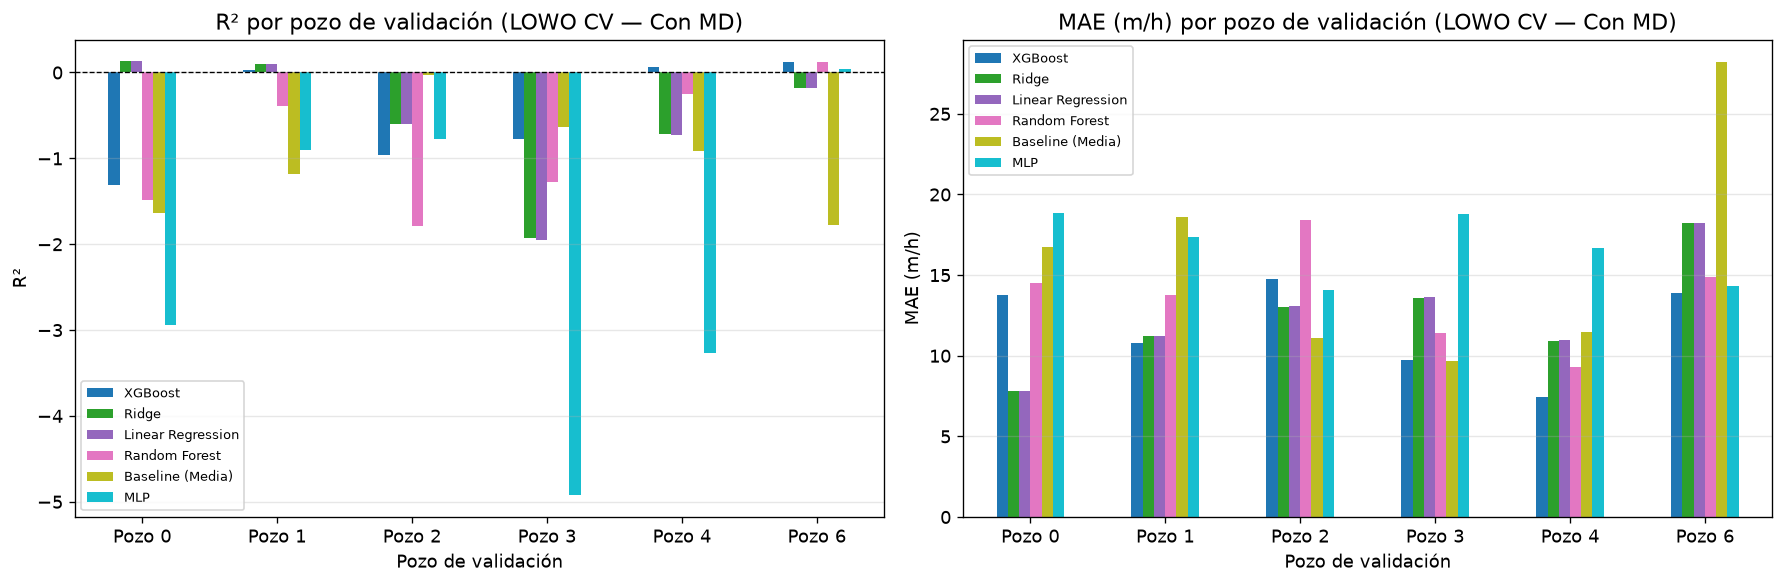


Tabla R² por pozo de validación:


modelo,XGBoost,Ridge,Linear Regression,Random Forest,Baseline (Media),MLP
fold,,,,,,
Pozo 0,-1.3089,0.1298,0.1299,-1.4891,-1.6329,-2.9437
Pozo 1,0.0313,0.0945,0.0947,-0.3880,-1.1851,-0.8984
Pozo 2,-0.9586,-0.5954,-0.6017,-1.7930,-0.0326,-0.7750
Pozo 3,-0.7795,-1.9252,-1.9472,-1.2778,-0.6333,-4.9249
Pozo 4,0.0662,-0.7162,-0.7264,-0.2457,-0.9163,-3.2698
Pozo 6,0.1233,-0.1773,-0.1771,0.1169,-1.7769,0.0435



Tabla MAE (m/h) por pozo de validación:


modelo,XGBoost,Ridge,Linear Regression,Random Forest,Baseline (Media),MLP
fold,,,,,,
Pozo 0,13.76,7.84,7.83,14.50,16.77,18.84
Pozo 1,10.76,11.24,11.23,13.74,18.62,17.35
Pozo 2,14.78,13.03,13.06,18.44,11.07,14.08
Pozo 3,9.72,13.57,13.63,11.39,9.67,18.76
Pozo 4,7.45,10.88,10.94,9.32,11.46,16.68
Pozo 6,13.91,18.23,18.24,14.91,28.19,14.32


In [12]:
orden_modelos = resumen_lowo.index.tolist()
pivot_r2  = lowo_bal.pivot(index='fold', columns='modelo', values='R²')[orden_modelos]
pivot_mae = lowo_bal.pivot(index='fold', columns='modelo', values='MAE')[orden_modelos]

fig, axes = plt.subplots(1, 2, figsize=(15, 5))
pivot_r2.plot(kind='bar', ax=axes[0], colormap='tab10')
axes[0].axhline(0, color='black', linewidth=0.8, linestyle='--')
axes[0].set_title('R² por pozo de validación (LOWO CV — Con MD)')
axes[0].set_xlabel('Pozo de validación'); axes[0].set_ylabel('R²')
axes[0].set_xticklabels(pivot_r2.index, rotation=0)
axes[0].grid(axis='y', alpha=0.3)
axes[0].legend(fontsize=8)

pivot_mae.plot(kind='bar', ax=axes[1], colormap='tab10')
axes[1].set_title('MAE (m/h) por pozo de validación (LOWO CV — Con MD)')
axes[1].set_xlabel('Pozo de validación'); axes[1].set_ylabel('MAE (m/h)')
axes[1].set_xticklabels(pivot_mae.index, rotation=0)
axes[1].grid(axis='y', alpha=0.3)
axes[1].legend(fontsize=8)
plt.tight_layout()
plt.show()

print('\nTabla R² por pozo de validación:')
display(pivot_r2.round(4))
print('\nTabla MAE (m/h) por pozo de validación:')
display(pivot_mae.round(2))

### Análisis de resultados por pozo en el LOWO

1. **Los modelos superan al `Baseline (Media)` en MAE:** Predecir siempre la media de los pozos de entrenamiento da un error medio de **$15,96\text{ m/h}$** ($R^2 = -1,03$). **XGBoost reduce ese error a $11,73\text{ m/h}$** ($-4,23\text{ m/h}$ menos de error absoluto), seguido por Ridge ($12,46\text{ m/h}$).
2. **Desempeño según el pozo:**
   - En **XGBoost**, los peores resultados ocurren en el **Pozo 2 ($R^2 = -0,95$)** y el **Pozo 3 ($R^2 = -0,96$)** (que presentaba correlaciones invertidas en presión y caudal en el EDA), mientras que en el **Pozo 4 obtiene $R^2 = -0,04$** y en el **Pozo 6 obtiene $R^2 = +0,02$**.
   - En los **Pozos 0 y 1 ganan los modelos lineales** (`Linear Regression` y `Ridge` logran $R^2 = +0,13$ en el Pozo 0 y $+0,09$ en el Pozo 1).

---

### Por qué descartamos normalizar el target por pozo (fuga de datos) y en su lugar eliminamos `Measured Depth m`

- **Fuga de datos al normalizar el target por pozo:** Si se estandariza el ROP de cada pozo (Z-score) y al validar se des-normaliza con la media y el desvío del propio pozo de validación, se incurre en *data leakage* (usando estadísticas futuras que en un pozo nuevo se desconocen). Si se des-normaliza honestamente usando la media y el desvío del entrenamiento, el $R^2$ de XGBoost cae a **$-1,70$**.
- **Corrección honesta — quitar `Measured Depth m`:** A continuación repetimos el LOWO CV eliminando `Measured Depth m` (dejando solo las **7 variables operativas**) para evitar que los modelos asocien profundidad alta exclusivamente con el bajo ROP de los pozos 3 y 4.

In [13]:
print('Corriendo LOWO CV SIN Measured Depth (solo 7 variables operativas)...')
lowo_bal_sin_md = lowo_cv(bal, MODELOS, drop_md=True)

resumen_lowo_sin_md = (
    lowo_bal_sin_md.groupby('modelo')[['R²', 'RMSE', 'MAE']]
    .agg(['mean', 'std']).round(4)
)
resumen_lowo_sin_md.columns = ['R² medio', 'R² std', 'RMSE medio', 'RMSE std', 'MAE medio', 'MAE std']
resumen_lowo_sin_md = resumen_lowo_sin_md.sort_values('MAE medio', ascending=True)

print('\n=== LOWO CV — Dataset Balanceado SIN Measured Depth (7 features operativas) ===')
display(resumen_lowo_sin_md)

Corriendo LOWO CV SIN Measured Depth (solo 7 variables operativas)...

=== LOWO CV — Dataset Balanceado SIN Measured Depth (7 features operativas) ===


,R² medio,R² std,RMSE medio,RMSE std,MAE medio,MAE std
modelo,,,,,,
XGBoost,-0.4708,0.3501,15.3072,2.7267,12.1595,2.3042
Random Forest,-0.5233,0.5780,15.2904,2.7432,12.2452,2.5217
Ridge,-0.4756,0.6429,15.0512,3.3642,12.4160,3.3895
Linear Regression,-0.4758,0.6434,15.0511,3.3638,12.4240,3.3886
Baseline (Media),-1.0295,0.6497,18.6986,7.7197,15.9627,6.9430
MLP,-2.4141,3.0274,20.8034,4.0681,17.6895,3.9655


Al quitar `Measured Depth m` en el LOWO CV:
- **Random Forest** mejora fuertemente: su $R^2$ medio sube de $-0,85$ a **$-0,52$** y su MAE baja de $13,72$ a **$12,25\text{ m/h}$**.
- **Ridge y Linear Regression** mejoran su $R^2$ medio de $-0,53$ a **$-0,48$**.
- **XGBoost** mantiene el mejor MAE ($12,16\text{ m/h}$) y reduce su variabilidad entre pozos casi a la mitad ($R^2\text{ std}$ baja de $0,62$ a $0,35$). Adoptamos este conjunto de **7 variables operativas (sin `pozo` y sin `Measured Depth m`)** para la evaluación final en el Pozo 5.

## 6. Evaluación final en Pozo 5 (holdout)

Usamos el conjunto de prueba reservado (**Pozo 5**: 908 filas, tramo de $8,5\text{''}$ / $215,9\text{ mm}$ entre $2.875\text{ y }3.793\text{ m}$, con ROP medio de $32,2\text{ m/h}$) para evaluar los modelos entrenados sobre todos los pozos de entrenamiento (`0, 1, 2, 3, 4, 6`), comparando el efecto de quitar `Measured Depth m`.

In [14]:
def evaluar_holdout(df_train_full, df_test, modelos, drop_md=False):
    """Entrena en todo el set de train y evalúa en el pozo test (sin incluir 'pozo')."""
    resultados = []
    predicciones = {}
    feats = get_features(df_train_full, drop_md=drop_md)

    X_tr = df_train_full[feats].values
    X_te = df_test[feats].values
    y_tr = df_train_full[TARGET].values
    y_te = df_test[TARGET].values

    for nombre, modelo in modelos.items():
        pipe = Pipeline([('scaler', RobustScaler()), ('modelo', modelo)])
        pipe.fit(X_tr, y_tr)
        y_pred = pipe.predict(X_te)
        predicciones[nombre] = y_pred
        resultados.append(metricas(y_te, y_pred, nombre, 'Pozo 5 (holdout)'))

    return pd.DataFrame(resultados), predicciones, y_te


bal_train = bal[bal['pozo'] != POZO_TEST].copy()

resultados_holdout_con_md, preds_con_md, y_true_p5 = evaluar_holdout(bal_train, test_p5, MODELOS, drop_md=False)
resultados_holdout_bal, preds_bal, _               = evaluar_holdout(bal_train, test_p5, MODELOS, drop_md=True)

comp_md_p5 = resultados_holdout_con_md[['modelo', 'R²', 'RMSE', 'MAE']].merge(
    resultados_holdout_bal[['modelo', 'R²', 'RMSE', 'MAE']],
    on='modelo', suffixes=(' (con MD)', ' (sin MD)')
).sort_values('MAE (sin MD)').reset_index(drop=True)

print('=== Holdout Pozo 5: Con Measured Depth (8 vars) vs. Sin Measured Depth (7 vars operativas) ===')
display(comp_md_p5)

=== Holdout Pozo 5: Con Measured Depth (8 vars) vs. Sin Measured Depth (7 vars operativas) ===


,modelo,R² (con MD),RMSE (con MD),MAE (con MD),R² (sin MD),RMSE (sin MD),MAE (sin MD)
0,XGBoost,-0.1083,16.0335,13.5304,0.1181,14.3024,11.7568
1,Random Forest,-0.2728,17.1827,13.6421,-0.1279,16.1748,13.2293
2,Baseline (Media),-0.0991,15.9668,14.0641,-0.0991,15.9668,14.0641
3,MLP,-1.2455,22.8228,18.7799,-0.7518,20.1583,17.0972
4,Ridge,-0.7321,20.0444,16.6303,-1.0125,21.6059,17.9226
5,Linear Regression,-0.7335,20.0523,16.6358,-1.0152,21.6205,17.9332


### Qué demuestra el resultado en el Pozo 5

1. **Con `Measured Depth m` incluido, ningún modelo supera claramente al Baseline:**
   - Predecir siempre la media del entrenamiento (`Baseline (Media)`) en el Pozo 5 da **$R^2 = -0,0991$** y **$\text{MAE} = 14,06\text{ m/h}$**.
   - Con `Measured Depth m`, **XGBoost** da $R^2 = -0,1083$ y $\text{MAE} = 13,53\text{ m/h}$, casi empatado con el baseline porque el Pozo 5 está entre $2.875\text{ y }3.793\text{ m}$, donde los únicos pozos de entrenamiento son los pozos lentos 3 y 4 ($\sim 21\text{ m/h}$).
2. **Al quitar `Measured Depth m` (7 variables operativas), XGBoost pasa a $R^2$ positivo:**
   - Guiándose únicamente por los parámetros mecánicos e hidráulicos, **XGBoost alcanza $R^2 = +0,1181$, baja el RMSE de $16,03$ a $14,30\text{ m/h}$ y reduce el MAE a $11,76\text{ m/h}$** (superando en $2,30\text{ m/h}$ al `Baseline (Media)`).
   - **Random Forest** también mejora su $R^2$ de $-0,2728$ a $-0,1279$ y su MAE de $13,64$ a $13,23\text{ m/h}$.

---

### Contraste con Baseline de Persistencia y prueba de calibración inicial en Pozo 5

Comprobamos dos aspectos prácticos adicionales sobre el Pozo 5:
1. **Baseline de persistencia ($\widehat{\text{ROP}}_t = \text{ROP}_{t-1}$):** Cuánto da predecir el ROP de cada metro usando el ROP medido en el metro inmediato anterior.
2. **Calibración con los primeros metros (30, 60 y 100 m):** Qué ocurre si intentamos corregir el sesgo promedio de XGBoost usando los primeros metros perforados del Pozo 5.

In [15]:
# 1. Baseline de persistencia en Pozo 5 (predecir el ROP del metro anterior)
r2_pers   = r2_score(y_true_p5[1:], y_true_p5[:-1])
rmse_pers = np.sqrt(mean_squared_error(y_true_p5[1:], y_true_p5[:-1]))
mae_pers  = mean_absolute_error(y_true_p5[1:], y_true_p5[:-1])
print(f'Baseline de Persistencia (ROP metro anterior) en Pozo 5 -> R²={r2_pers:.4f} | RMSE={rmse_pers:.2f} m/h | MAE={mae_pers:.2f} m/h\n')

# 2. Prueba de calibración corrigiendo el sesgo con los primeros 30, 60 y 100 m del Pozo 5
d_min = test_p5['Measured Depth m'].min()
pred_xgb_p5 = preds_bal['XGBoost']

filas_cal = []
for m_cal in [30, 60, 100]:
    mask_ini = (test_p5['Measured Depth m'] - d_min) <= m_cal
    sesgo_ini = (y_true_p5[mask_ini] - pred_xgb_p5[mask_ini]).mean()
    y_resto = y_true_p5[~mask_ini]
    pred_sin_cal = pred_xgb_p5[~mask_ini]
    pred_con_cal = pred_sin_cal + sesgo_ini
    filas_cal.append({
        'Tramo de calibración': f'Primeros {m_cal} m',
        'Sesgo estimado (m/h)': round(sesgo_ini, 2),
        'MAE resto sin calibrar (m/h)': round(mean_absolute_error(y_resto, pred_sin_cal), 2),
        'MAE resto calibrado (m/h)': round(mean_absolute_error(y_resto, pred_con_cal), 2)
    })

df_cal = pd.DataFrame(filas_cal)
print('=== Prueba de calibración inicial en Pozo 5 (XGBoost sin MD) ===')
display(df_cal)

Baseline de Persistencia (ROP metro anterior) en Pozo 5 -> R²=0.6708 | RMSE=8.73 m/h | MAE=4.42 m/h

=== Prueba de calibración inicial en Pozo 5 (XGBoost sin MD) ===


,Tramo de calibración,Sesgo estimado (m/h),MAE resto sin calibrar (m/h),MAE resto calibrado (m/h)
0,Primeros 30 m,21.18,11.33,19.14
1,Primeros 60 m,5.11,11.39,10.79
2,Primeros 100 m,0.31,11.65,11.55


- **Persistencia en tiempo real:** Predecir con el ROP del metro anterior da **$R^2 = 0,6708$ y $\text{MAE} = 4,42\text{ m/h}$**, muy por encima de cualquier modelo estático que no incorpore valores recientes de ROP.
- **La calibración con los primeros metros no es consistente:** Con los primeros 30 m el error empeora de $11,33$ a $19,14\text{ m/h}$, con 60 m baja levemente a $10,79\text{ m/h}$ y con 100 m queda prácticamente igual ($11,55\text{ m/h}$), porque la formación varía a lo largo del pozo.

## 7. Predicho vs Real y Distribución de Residuos — Pozo 5 (sin MD)

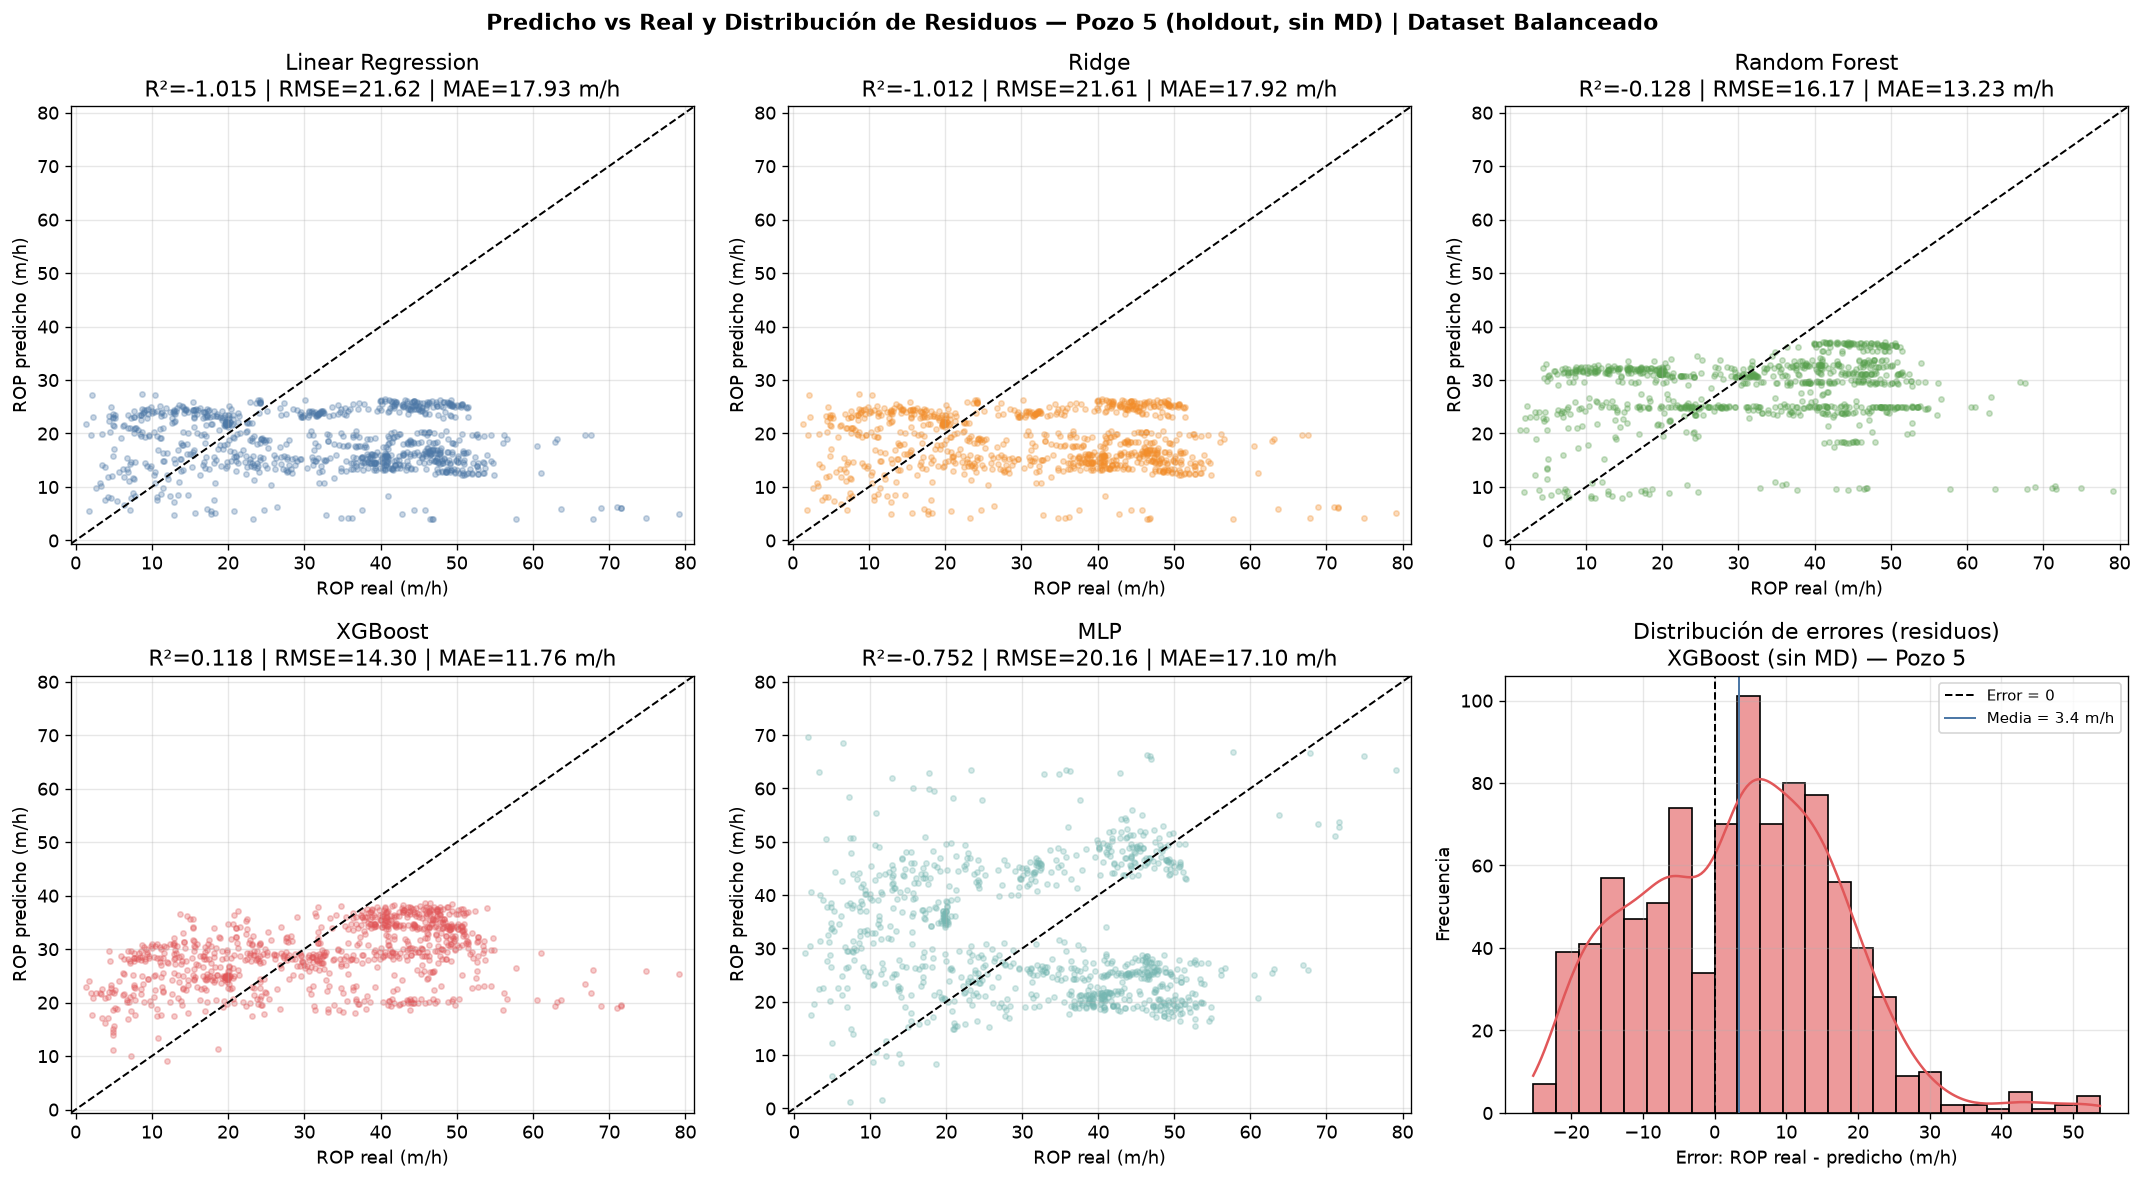

In [16]:
modelos_plot = ['Linear Regression', 'Ridge', 'Random Forest', 'XGBoost', 'MLP']
fig, axes = plt.subplots(2, 3, figsize=(18, 10))
axes = axes.flatten()
colors = ['#4e79a7', '#f28e2b', '#59a14f', '#e15759', '#76b7b2']

for i, nombre in enumerate(modelos_plot):
    y_pred = preds_bal[nombre]
    ax = axes[i]
    r2 = r2_score(y_true_p5, y_pred)
    rmse = np.sqrt(mean_squared_error(y_true_p5, y_pred))
    mae = mean_absolute_error(y_true_p5, y_pred)

    ax.scatter(y_true_p5, y_pred, alpha=0.3, s=10, color=colors[i])
    lim = [min(y_true_p5.min(), y_pred.min()) - 2,
           max(y_true_p5.max(), y_pred.max()) + 2]
    ax.plot(lim, lim, 'k--', linewidth=1.2, label='Ideal')
    ax.set_xlim(lim); ax.set_ylim(lim)
    ax.set_title(f'{nombre}\nR²={r2:.3f} | RMSE={rmse:.2f} | MAE={mae:.2f} m/h')
    ax.set_xlabel('ROP real (m/h)')
    ax.set_ylabel('ROP predicho (m/h)')
    ax.grid(alpha=0.3)

# Histograma de residuos del mejor modelo (XGBoost) en el 6.º subplot
residuos_xgb = y_true_p5 - preds_bal['XGBoost']
sns.histplot(residuos_xgb, bins=25, kde=True, ax=axes[-1], color='#e15759', alpha=0.6)
axes[-1].axvline(0, color='black', linestyle='--', linewidth=1.2, label='Error = 0')
axes[-1].axvline(residuos_xgb.mean(), color='#4e79a7', linestyle='-', linewidth=1.2,
                 label=f'Media = {residuos_xgb.mean():.1f} m/h')
axes[-1].set_title('Distribución de errores (residuos)\nXGBoost (sin MD) — Pozo 5')
axes[-1].set_xlabel('Error: ROP real - predicho (m/h)')
axes[-1].set_ylabel('Frecuencia')
axes[-1].legend(fontsize=9)
axes[-1].grid(alpha=0.3)

plt.suptitle('Predicho vs Real y Distribución de Residuos — Pozo 5 (holdout, sin MD) | Dataset Balanceado',
             fontsize=13, fontweight='bold')
plt.tight_layout()
plt.show()

## 8. Feature Importance — Random Forest y XGBoost (7 variables operativas)

Importancia relativa de las 7 variables operativas (sin `pozo` ni `Measured Depth m`).

> **Nota de interpretación (Clases 17 y 18):** Las importancias indican qué variables utiliza cada modelo para dividir los árboles, pero **no prueban causalidad** y pueden repartirse entre variables correlacionadas (como diámetro, caudal y hookload).

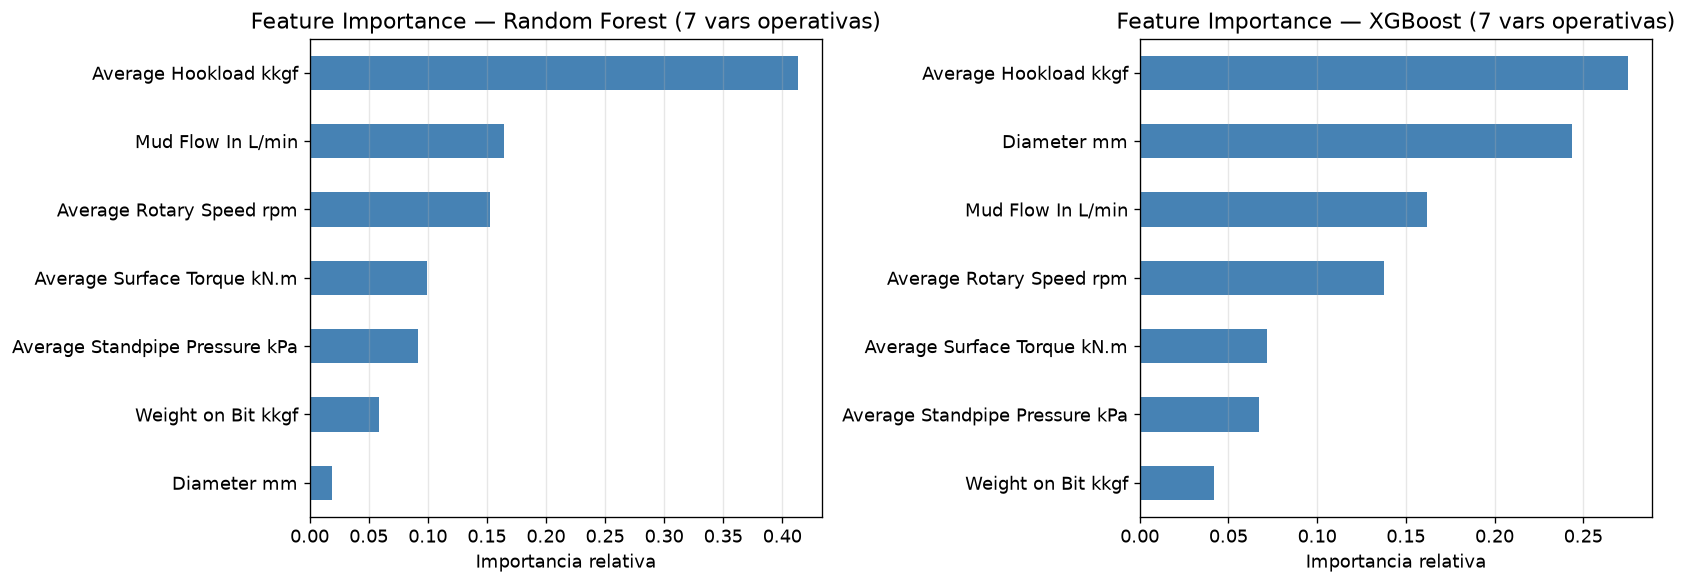

In [17]:
feats7 = get_features(bal, drop_md=True)
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

for ax, nombre in zip(axes, ['Random Forest', 'XGBoost']):
    modelo = MODELOS[nombre]
    importances = pd.Series(modelo.feature_importances_,
                            index=feats7).sort_values(ascending=True)
    importances.plot(kind='barh', ax=ax, color='steelblue')
    ax.set_title(f'Feature Importance — {nombre} (7 vars operativas)')
    ax.set_xlabel('Importancia relativa')
    ax.grid(axis='x', alpha=0.3)

plt.tight_layout()
plt.show()

## 9. Perfil de ROP vs profundidad — Pozo 5

Comparamos la curva de ROP real vs. predicha a lo largo de la profundidad medida del Pozo 5.

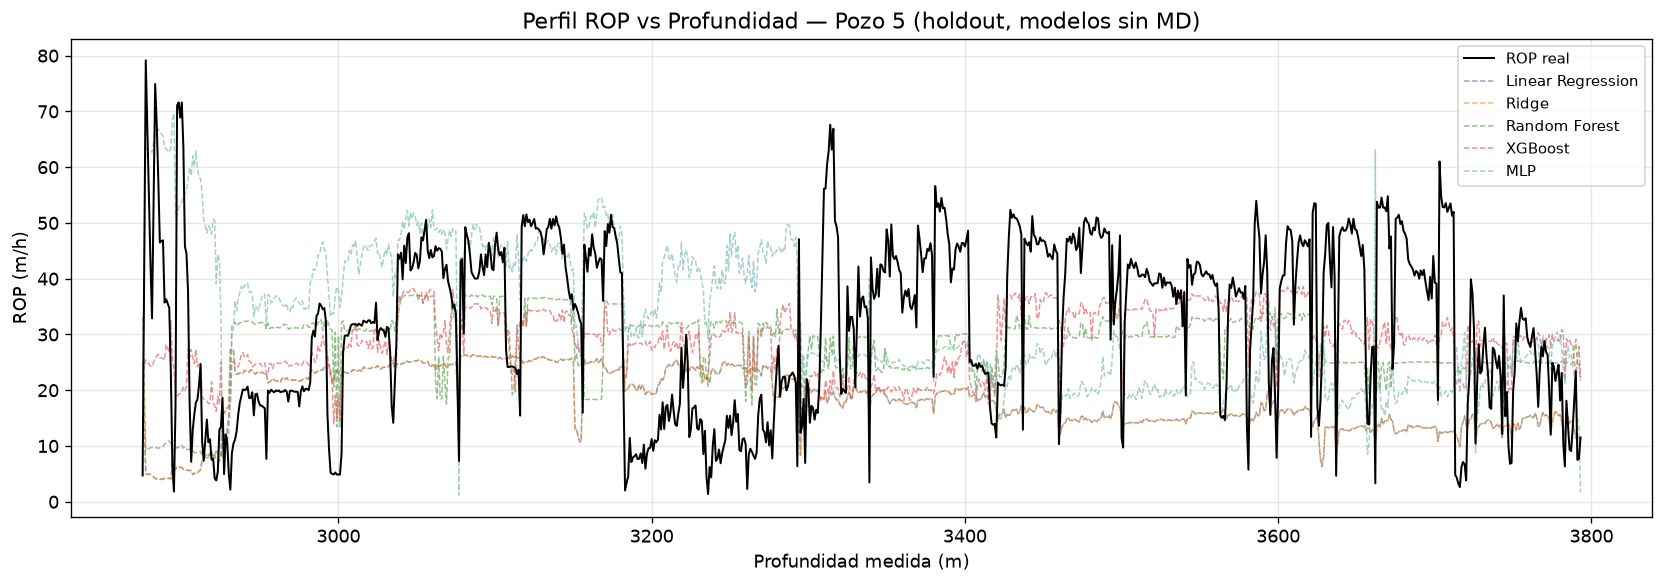

In [18]:
depth_col = 'Measured Depth m'
depth_p5 = test_p5[depth_col].values

fig, ax = plt.subplots(figsize=(14, 5))
ax.plot(depth_p5, y_true_p5, color='black', linewidth=1.2, label='ROP real', zorder=5)

colores = ['#4e79a7', '#f28e2b', '#59a14f', '#e15759', '#76b7b2']
for nombre, color in zip(modelos_plot, colores):
    ax.plot(depth_p5, preds_bal[nombre], alpha=0.65, linewidth=0.9, linestyle='--',
            color=color, label=nombre)

ax.set_xlabel('Profundidad medida (m)')
ax.set_ylabel('ROP (m/h)')
ax.set_title('Perfil ROP vs Profundidad — Pozo 5 (holdout, modelos sin MD)')
ax.legend(loc='upper right', fontsize=9)
ax.grid(alpha=0.3)
plt.tight_layout()
plt.show()

---

# Parte 2 — Repetición con dataset completo (sin balancear, 7 variables operativas)

Usamos `conjunto_limpio.csv` (34.456 filas, donde los pozos 3 y 4 concentran casi el 80% de las filas por su mayor frecuencia de muestreo) con las mismas 7 variables operativas (sin `pozo` ni `Measured Depth m`) para evaluar el impacto del desbalanceo de muestreo.

In [19]:
print('Corriendo Leave-One-Well-Out CV en dataset COMPLETO (sin MD)...')
lowo_full = lowo_cv(full, MODELOS, drop_md=True)

resumen_lowo_full = (
    lowo_full
    .groupby('modelo')[['R²', 'RMSE', 'MAE']]
    .agg(['mean', 'std'])
    .round(4)
)
resumen_lowo_full.columns = ['R² medio', 'R² std', 'RMSE medio', 'RMSE std', 'MAE medio', 'MAE std']
resumen_lowo_full = resumen_lowo_full.sort_values('MAE medio', ascending=True)

print('\n=== LOWO CV — Dataset Completo (sin MD) ===')
display(resumen_lowo_full)

Corriendo Leave-One-Well-Out CV en dataset COMPLETO (sin MD)...

=== LOWO CV — Dataset Completo (sin MD) ===


,R² medio,R² std,RMSE medio,RMSE std,MAE medio,MAE std
modelo,,,,,,
XGBoost,-0.4911,0.4537,15.2505,3.0891,12.4676,2.7126
Linear Regression,-0.8536,1.1053,16.4070,4.2285,13.7316,4.2683
Ridge,-0.8531,1.1025,16.4078,4.2261,13.7323,4.2653
Random Forest,-1.0528,0.9069,17.3611,3.4855,14.4643,3.1288
Baseline (Media),-1.2781,1.1498,19.5124,8.9756,16.9733,8.1103
MLP,-2.7715,2.9993,22.1158,5.9189,18.3975,5.7076


In [20]:
full_train = full[full['pozo'] != POZO_TEST].copy()

print('Evaluando en holdout (Pozo 5) — Dataset Completo (sin MD)...')
resultados_holdout_full, preds_full, _ = evaluar_holdout(full_train, test_p5, MODELOS, drop_md=True)

print('\n=== Holdout Pozo 5 — Dataset Completo (sin MD) ===')
display(resultados_holdout_full.sort_values('MAE', ascending=True).reset_index(drop=True))

Evaluando en holdout (Pozo 5) — Dataset Completo (sin MD)...

=== Holdout Pozo 5 — Dataset Completo (sin MD) ===


,modelo,fold,R²,RMSE,MAE
0,Random Forest,Pozo 5 (holdout),0.1046,14.4120,11.7636
1,XGBoost,Pozo 5 (holdout),0.0352,14.9598,12.4409
2,MLP,Pozo 5 (holdout),-0.1867,16.5914,13.0390
3,Baseline (Media),Pozo 5 (holdout),-0.2633,17.1187,14.8055
4,Ridge,Pozo 5 (holdout),-0.6644,19.6487,16.3415
5,Linear Regression,Pozo 5 (holdout),-0.6648,19.6512,16.3435


---

# Parte 3 — Comparación final en Pozo 5: balanceado vs. completo

Tabla unificada y gráfico comparativo en el Pozo 5 (usando las 7 variables operativas sin `Measured Depth m`).

In [21]:
comp_bal  = resultados_holdout_bal[['modelo', 'R²', 'RMSE', 'MAE']].copy()
comp_full = resultados_holdout_full[['modelo', 'R²', 'RMSE', 'MAE']].copy()

comp_bal.columns  = ['Modelo', 'R² (bal)', 'RMSE (bal)', 'MAE (bal)']
comp_full.columns = ['Modelo', 'R² (full)', 'RMSE (full)', 'MAE (full)']

comparacion = comp_bal.merge(comp_full, on='Modelo').sort_values('MAE (bal)', ascending=True).reset_index(drop=True)
print('=== Comparación holdout Pozo 5 (sin MD): balanceado vs completo ===')
display(comparacion)

=== Comparación holdout Pozo 5 (sin MD): balanceado vs completo ===


,Modelo,R² (bal),RMSE (bal),MAE (bal),R² (full),RMSE (full),MAE (full)
0,XGBoost,0.1181,14.3024,11.7568,0.0352,14.9598,12.4409
1,Random Forest,-0.1279,16.1748,13.2293,0.1046,14.4120,11.7636
2,Baseline (Media),-0.0991,15.9668,14.0641,-0.2633,17.1187,14.8055
3,MLP,-0.7518,20.1583,17.0972,-0.1867,16.5914,13.0390
4,Ridge,-1.0125,21.6059,17.9226,-0.6644,19.6487,16.3415
5,Linear Regression,-1.0152,21.6205,17.9332,-0.6648,19.6512,16.3435


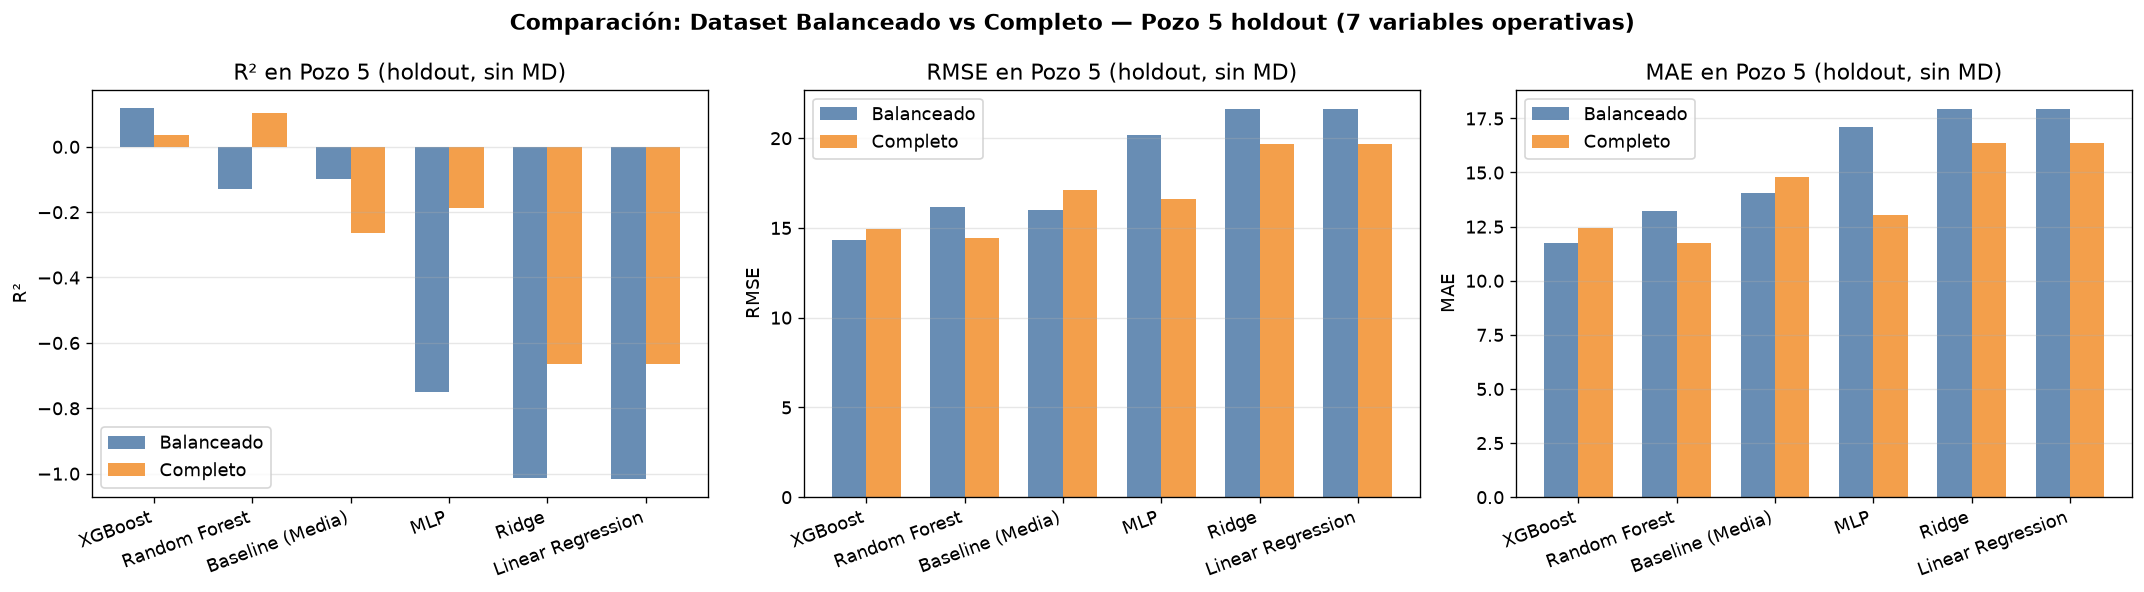

In [22]:
fig, axes = plt.subplots(1, 3, figsize=(18, 5))
metricas_comp = [('R²', True), ('RMSE', False), ('MAE', False)]

for ax, (met, _) in zip(axes, metricas_comp):
    x = np.arange(len(comparacion))
    w = 0.35
    ax.bar(x - w/2, comparacion[f'{met} (bal)'],  w, label='Balanceado', color='#4e79a7', alpha=0.85)
    ax.bar(x + w/2, comparacion[f'{met} (full)'], w, label='Completo',   color='#f28e2b', alpha=0.85)
    ax.set_xticks(x)
    ax.set_xticklabels(comparacion['Modelo'], rotation=20, ha='right')
    ax.set_title(f'{met} en Pozo 5 (holdout, sin MD)')
    ax.set_ylabel(met)
    ax.legend()
    ax.grid(axis='y', alpha=0.3)

plt.suptitle('Comparación: Dataset Balanceado vs Completo — Pozo 5 holdout (7 variables operativas)',
             fontsize=13, fontweight='bold')
plt.tight_layout()
plt.show()

---

## Conclusiones

### 1. El split aleatorio 80/20 sobreestima el rendimiento incluso dentro de un mismo pozo
Al mezclar filas sueltas al azar (80/20), XGBoost obtiene $R^2 = 0,89$ ($\text{MAE} = 3,00\text{ m/h}$) y Random Forest $R^2 = 0,86$. Sin embargo, al particionar por **bloques contiguos de 100 m de profundidad**, el $R^2$ cae a **$0,58$** en XGBoost ($\text{MAE} = 5,85\text{ m/h}$) y a **$0,54$** en Random Forest. Esto demuestra que gran parte del $0,89$ proviene de interpolar entre metros vecinos con la misma roca y condiciones operativas.

### 2. Qué significa realmente el $R^2$ negativo en LOWO y por qué importa comparar contra el Baseline en MAE
En la validación *Leave-One-Well-Out* (LOWO), el $R^2$ se calcula contra la media del pozo de validación (un valor imposible de conocer antes de perforarlo), dando promedios negativos ($R^2 = -0,47$ en XGBoost). Sin embargo, al comparar contra el **`Baseline (Media)` del entrenamiento** ($\text{MAE} = 15,96\text{ m/h}$, $R^2 = -1,03$), los modelos reducen el error medio absoluto en más de $3,5\text{–}4,2\text{ m/h}$ (**XGBoost $\text{MAE} = 11,73\text{ m/h}$ con MD y $12,16\text{ m/h}$ sin MD; Random Forest $\text{MAE} = 12,25\text{ m/h}$ sin MD**). Tampoco existe un único ganador universal en todos los folds: en los pozos 0 y 1 los modelos lineales (`Ridge` y `Linear Regression`, $R^2 = +0,13\text{ y }+0,09$) superan a los árboles, mientras que los folds más adversos para XGBoost son los **pozos 2 y 3** ($R^2 \approx -0,95$), y en los **pozos 4 y 6** alcanza $R^2 \approx -0,04\text{ y }+0,02$.

### 3. La normalización Z-score por pozo no es aplicable a pozos nuevos sin fuga de datos
Estandarizar el ROP de cada pozo antes de entrenar solo mejoraba el $R^2$ (a $-0,17$) cuando se des-normalizaba usando la media y el desvío del propio pozo de validación (*target leakage*). Cuando se des-normaliza honestamente con estadísticas del entrenamiento, el $R^2$ cae a **$-1,70$**.

### 4. Eliminar `Measured Depth m` corrige el *depth confounding* y lleva al Pozo 5 a $R^2$ positivo
En el Pozo 5 (perforado íntegramente en $8,5\text{''}$ entre $2.875\text{ y }3.793\text{ m}$, con ROP medio de $32,2\text{ m/h}$), incluir la profundidad medida (`Measured Depth m`) hacía que los árboles lo asimilaran a los únicos pozos profundos de entrenamiento (Pozos 3 y 4, de $\sim 21\text{ m/h}$), obteniendo $R^2 = -0,11$ y $\text{MAE} = 13,53\text{ m/h}$, casi empatado con el `Baseline (Media)` ($R^2 = -0,10$, $\text{MAE} = 14,06\text{ m/h}$). **Al quitar `Measured Depth m` y `pozo` (entrenando solo con las 7 variables operativas), XGBoost pasa a $R^2 = +0,1181$ y reduce el MAE a $11,76\text{ m/h}$** en el dataset balanceado (y **Random Forest alcanza $R^2 = +0,1046$ y $\text{MAE} = 11,76\text{ m/h}$** en el dataset completo).

### 5. Límites frente a la persistencia y ausencia de litología (`Gamma Ray`)
Si bien en el Notebook 2 verificamos que los 6 pozos tienen **rangos operativos comparables** tras la limpieza, la respuesta del ROP ante esos mismos parámetros cambia entre formaciones porque el dataset unificado carece de indicadores litológicos (`Gamma Ray`). Por eso:
- En un escenario de perforación en vivo (donde ya se conoce el ROP del metro anterior), el **baseline de persistencia ($\widehat{\text{ROP}}_t = \text{ROP}_{t-1}$) alcanza $R^2 = 0,67$ y $\text{MAE} = 4,42\text{ m/h}$** en el Pozo 5, superando a los modelos estáticos que no incorporan memoria temporal.
- Corregir un sesgo fijo con los primeros 30, 60 o 100 metros del Pozo 5 resulta inestable ($\text{MAE}$ de $19,14\text{ m/h}$, $10,79\text{ m/h}$ y $11,55\text{ m/h}$ respectivamente), porque el inicio del tramo no representa los cambios de roca posteriores. Para mejorar la predicción cross-well y en tiempo real se requiere incorporar **variables de litología (`Gamma Ray`)** o **variables autorregresivas (ROP de los metros previos)**.